# **RECIPE GEOFISIKA: QA/QC KATALOG GEMPA DAN GUTENBERG–RICHTER**
## **NAMA :** Asrul 
## **NIM  :** H061251033
## **KELAS :** A

**Recipe ID:** R-SES-001  
**Prompt ID:** P-SES-001  

**Tujuan:** memeriksa kualitas katalog gempa, merangkum statistik dasar, dan membuat estimasi eksploratif hubungan Gutenberg–Richter. Analisis ini bukan alat prediksi gempa.

**Alur:** Problem → Minimal Theory → Prompt → Code → Result → Optional Check.

### **1. Problem**

Katalog gempa mungkin mengandung nilai kosong, duplikasi, atau koordinat, kedalaman, dan magnitudo yang tidak masuk akal. Recipe ini menandai masalah tersebut sebelum membuat ringkasan dan grafik magnitudo–frekuensi.

### **2. Minimal Theory**

Hukum Gutenberg – Richter:

\[\log_{10} N(M\geq m)=a-bm\]

`N(M ≥ m)` adalah jumlah gempa dengan magnitudo sama dengan atau lebih besar dari ambang `m`. Parameter `b` di sini dihitung dengan regresi linear sederhana pada kurva kumulatif, sehingga hanya merupakan estimasi eksploratif. Nilai tersebut dipengaruhi kelengkapan katalog, rentang magnitudo, interval waktu, dan wilayah.

Batas QC dasar: lintang −90 hingga 90°, bujur −180 hingga 180°, kedalaman ≥ 0 km, dan magnitudo pada rentang pemeriksaan −2 hingga 10. Batas ini adalah pemeriksaan umum, bukan pengganti validasi metadata sumber.

### **3. Input dan Constraint Contract**

Kolom wajib: `time`, `latitude`, `longitude`, `depth_km`, `magnitude`.

- `time`: tanggal/waktu yang dapat diparse.
- `latitude`, `longitude`: derajat desimal.
- `depth_km`: kilometer.
- `magnitude`: nilai magnitudo katalog.
- Mode contoh memakai data sintetis yang dibangkitkan di notebook.
- Untuk data sendiri, ubah `USE_SYNTHETIC = False` dan letakkan `earthquake_catalog.csv` di direktori kerja.
- Data mentah tidak ditimpa. Baris bermasalah diberi flag dan alasan.
- Tidak ada pengambilan data melalui jaringan.

### **4. Prompt reusable (P-SES-001)**

> Bertindak sebagai asisten analisis data seismologi yang teliti. Audit file katalog gempa dengan kolom `time`, `latitude`, `longitude`, `depth_km`, dan `magnitude`. Periksa skema, nilai kosong, duplikasi, rentang koordinat, kedalaman, dan magnitudo. Jangan mengubah file mentah atau mengambil data dari jaringan. Hasilkan tabel QC, statistik ringkas, grafik Gutenberg–Richter, estimasi slope eksploratif bila data cukup, dan run record. Jelaskan batas interpretasi dan jangan menyebut hasil sebagai prediksi gempa.

### **5. Code — Persiapan dan pengaturan**

In [ ]:
import json, hashlib, platform, sys
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RECIPE_ID = "R-SES-001"
PROMPT_ID = "P-SES-001"
USE_SYNTHETIC = True
INPUT_FILE = Path("earthquake_catalog.csv")
OUTPUT_DIR = Path("results_r_ses_001")
OUTPUT_DIR.mkdir(exist_ok=True)

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Recipe:", RECIPE_ID)

Python: 3.13.5
NumPy: 2.3.5
Pandas: 2.2.3
Recipe: R-SES-001


### **6. Code — Membuat atau memuat katalog**

In [ ]:
if USE_SYNTHETIC:
    # Data sintetis untuk menguji alur; bukan katalog gempa nyata.
    rng = np.random.default_rng(20261021)
    n = 80
    mags = np.clip(rng.exponential(scale=0.75, size=n) + 1.5, 1.5, 5.8)
    df = pd.DataFrame({
        "time": pd.date_range("2024-01-01", periods=n, freq="7D").astype(str),
        "latitude": rng.uniform(-8.5, 1.5, n),
        "longitude": rng.uniform(118.0, 130.0, n),
        "depth_km": rng.uniform(3, 180, n),
        "magnitude": np.round(mags, 1)
    })
    # Cacat sengaja agar pemeriksaan QC dapat diuji
    df.loc[3, "latitude"] = 95.0
    df.loc[7, "depth_km"] = -4.0
    df.loc[10, "magnitude"] = np.nan
    df = pd.concat([df, df.iloc[[15]]], ignore_index=True)  # duplikasi sengaja
    source_status = "SYNTHETIC — bukan data observasi"
else:
    if not INPUT_FILE.exists():
        raise FileNotFoundError(f"File tidak ditemukan: {INPUT_FILE.resolve()}")
    df = pd.read_csv(INPUT_FILE)
    source_status = f"USER FILE — {INPUT_FILE}"

required = ["time", "latitude", "longitude", "depth_km", "magnitude"]
missing_cols = [c for c in required if c not in df.columns]
if missing_cols:
    raise ValueError(f"Kolom wajib tidak tersedia: {missing_cols}")

raw_hash = hashlib.sha256(df.to_csv(index=False).encode("utf-8")).hexdigest()
print("Sumber:", source_status)
print("Ukuran katalog (baris, kolom):", df.shape)
display(df.head())

Sumber: SYNTHETIC — bukan data observasi
Ukuran katalog (baris, kolom): (81, 5)


,time,latitude,longitude,depth_km,magnitude
0,2024-01-01,-1.445855,127.133287,10.516952,1.9
1,2024-01-08,-7.510125,123.667069,56.775322,1.5
2,2024-01-15,-6.037818,129.920747,50.530222,1.7
3,2024-01-22,95.000000,127.886863,79.120362,1.6
4,2024-01-29,-5.518035,122.157154,178.092699,1.5


### **7. Code — Pemeriksaan kualitas data (QA/QC)**

In [ ]:
qc = df.copy()
qc["time_parsed"] = pd.to_datetime(qc["time"], errors="coerce", utc=True)
numeric_cols = ["latitude", "longitude", "depth_km", "magnitude"]
for col in numeric_cols:
    qc[col] = pd.to_numeric(qc[col], errors="coerce")

reasons = [[] for _ in range(len(qc))]
for i, row in qc.iterrows():
    if pd.isna(row["time_parsed"]):
        reasons[i].append("waktu kosong/tidak terbaca")
    for col in numeric_cols:
        if pd.isna(row[col]):
            reasons[i].append(f"{col} kosong/non-numerik")
    if pd.notna(row["latitude"]) and not -90 <= row["latitude"] <= 90:
        reasons[i].append("latitude di luar [-90, 90]")
    if pd.notna(row["longitude"]) and not -180 <= row["longitude"] <= 180:
        reasons[i].append("longitude di luar [-180, 180]")
    if pd.notna(row["depth_km"]) and row["depth_km"] < 0:
        reasons[i].append("kedalaman negatif")
    if pd.notna(row["magnitude"]) and not -2 <= row["magnitude"] <= 10:
        reasons[i].append("magnitudo di luar rentang pemeriksaan")

# Tandai semua baris yang identik pada kolom inti; tidak menghapus data mentah
duplicate_mask = qc[required].duplicated(keep=False)
for i in np.where(duplicate_mask.to_numpy())[0]:
    reasons[i].append("duplikasi pada kolom inti")

qc["qc_reasons"] = ["; ".join(x) for x in reasons]
qc["qc_flag"] = qc["qc_reasons"].ne("")
print("Jumlah baris:", len(qc))
print("Baris ter-flag:", int(qc["qc_flag"].sum()))
print("Nilai kosong/non-numerik:")
display(qc[required].isna().sum().rename("count").to_frame())
display(qc.loc[qc["qc_flag"], required + ["qc_flag", "qc_reasons"]].head(20))

Jumlah baris: 81
Baris ter-flag: 5
Nilai kosong/non-numerik:


,count
time,0
latitude,0
longitude,0
depth_km,0
magnitude,1


,time,latitude,longitude,depth_km,magnitude,qc_flag,qc_reasons
3,2024-01-22,95.000000,127.886863,79.120362,1.6,True,"latitude di luar [-90, 90]"
7,2024-02-19,1.342865,120.409949,-4.000000,2.1,True,kedalaman negatif
10,2024-03-11,-1.114105,124.506415,25.083858,NaN,True,magnitude kosong/non-numerik
15,2024-04-15,-6.394604,127.849281,67.976055,3.8,True,duplikasi pada kolom inti
80,2024-04-15,-6.394604,127.849281,67.976055,3.8,True,duplikasi pada kolom inti


### **8. Code — Statistik ringkas dan kurva Gutenberg–Richter**

In [ ]:
# Analisis memakai baris yang lolos QC dasar. Tidak ada baris yang dihapus dari tabel QC.
valid = qc.loc[~qc["qc_flag"]].copy()
if len(valid) < 5:
    raise ValueError("Data valid kurang dari 5 baris; statistik Gutenberg–Richter tidak dihitung.")

summary = {
    "recipe_id": RECIPE_ID,
    "source_status": source_status,
    "n_rows_input": int(len(df)),
    "n_flagged": int(qc["qc_flag"].sum()),
    "n_valid_for_analysis": int(len(valid)),
    "time_min": str(valid["time_parsed"].min()),
    "time_max": str(valid["time_parsed"].max()),
    "magnitude_min": float(valid["magnitude"].min()),
    "magnitude_median": float(valid["magnitude"].median()),
    "magnitude_max": float(valid["magnitude"].max()),
    "depth_median_km": float(valid["depth_km"].median())
}
display(pd.DataFrame([summary]).T.rename(columns={0: "value"}))

# Hitung N(M >= m) pada ambang 0.5 unit, berdasarkan data valid.
mag = valid["magnitude"].to_numpy()
thresholds = np.arange(np.floor(mag.min() * 2) / 2, mag.max() + 0.25, 0.5)
counts = np.array([(mag >= m).sum() for m in thresholds], dtype=int)
curve = pd.DataFrame({"magnitude_threshold": thresholds, "N_cumulative": counts})
curve = curve[curve["N_cumulative"] > 0].copy()
curve["log10_N"] = np.log10(curve["N_cumulative"])

# Fit hanya jika terdapat minimal 3 titik berbeda dengan jumlah kumulatif positif.
if len(curve) >= 3 and curve["magnitude_threshold"].nunique() >= 3:
    slope, intercept = np.polyfit(curve["magnitude_threshold"], curve["log10_N"], 1)
    b_estimate = float(-slope)
else:
    slope, intercept, b_estimate = np.nan, np.nan, np.nan

print("Estimasi b eksploratif:", b_estimate)
display(curve)

,value
recipe_id,R-SES-001
source_status,SYNTHETIC — bukan data observasi
n_rows_input,81
n_flagged,5
n_valid_for_analysis,76
time_min,2024-01-01 00:00:00+00:00
time_max,2025-07-07 00:00:00+00:00
magnitude_min,1.5
magnitude_median,1.9
magnitude_max,5.0


Estimasi b eksploratif: 0.534189014304803


,magnitude_threshold,N_cumulative,log10_N
0,1.5,76,1.880814
1,2.0,37,1.568202
2,2.5,17,1.230449
3,3.0,7,0.845098
4,3.5,5,0.698970
5,4.0,2,0.301030
6,4.5,2,0.301030
7,5.0,1,0.000000


### **9. Code — Verifikasi dan visualisasi**

PASS - Kolom wajib tersedia 
PASS - Tabel QC mempertahankan jumlah baris input 81 == 81
PASS - Jumlah kumulatif tidak meningkat saat ambang magnitudo naik 
PASS - Semua baris ter-flag memiliki alasan 
PASS - Hash representasi tabel sumber tercatat 


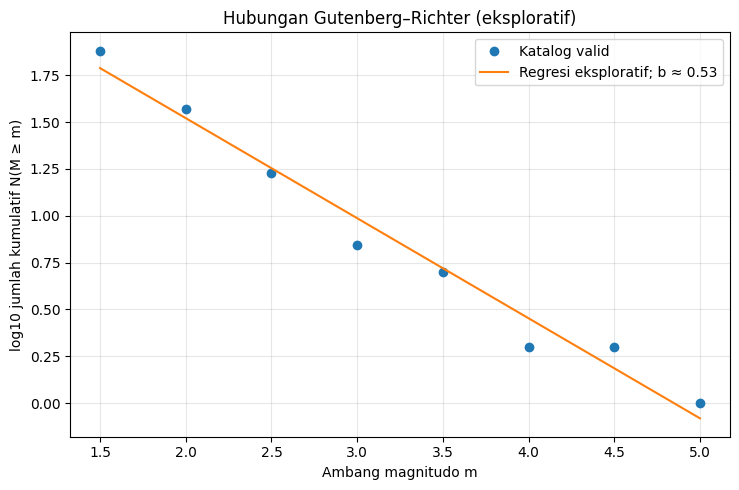

Grafik disimpan: results_r_ses_001/gutenberg_richter.png


In [ ]:
checks = []
def record_check(name, passed, detail=""):
    checks.append({"check": name, "passed": bool(passed), "detail": str(detail)})
    print(("PASS" if passed else "FAIL"), "-", name, detail)

record_check("Kolom wajib tersedia", all(c in df.columns for c in required))
record_check("Tabel QC mempertahankan jumlah baris input", len(qc) == len(df),
             f"{len(qc)} == {len(df)}")
record_check("Jumlah kumulatif tidak meningkat saat ambang magnitudo naik",
             bool(np.all(np.diff(curve["N_cumulative"].to_numpy()) <= 0)))
record_check("Semua baris ter-flag memiliki alasan",
             bool(qc.loc[qc["qc_flag"], "qc_reasons"].str.len().gt(0).all()))
record_check("Hash representasi tabel sumber tercatat", len(raw_hash) == 64)

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.plot(curve["magnitude_threshold"], curve["log10_N"], "o", label="Katalog valid")
if np.isfinite(slope):
    xfit = np.linspace(curve["magnitude_threshold"].min(),
                       curve["magnitude_threshold"].max(), 100)
    ax.plot(xfit, slope*xfit + intercept, "-", label=f"Regresi eksploratif; b ≈ {b_estimate:.2f}")
ax.set_xlabel("Ambang magnitudo m")
ax.set_ylabel("log10 jumlah kumulatif N(M ≥ m)")
ax.set_title("Hubungan Gutenberg–Richter (eksploratif)")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
figure_path = OUTPUT_DIR / "gutenberg_richter.png"
fig.savefig(figure_path, dpi=160)
plt.show()
print("Grafik disimpan:", figure_path)

### **10. Result — Simpan artifact dan run record**

In [ ]:
qc.to_csv(OUTPUT_DIR / "catalog_qc.csv", index=False)
curve.to_csv(OUTPUT_DIR / "gutenberg_richter_counts.csv", index=False)

summary["b_estimate_exploratory"] = b_estimate if np.isfinite(b_estimate) else None
summary["checks_passed"] = int(sum(c["passed"] for c in checks))
summary["checks_total"] = len(checks)
summary["raw_table_sha256"] = raw_hash
summary["run_timestamp_utc"] = datetime.now(timezone.utc).isoformat()
summary["python_version"] = sys.version.split()[0]
summary["numpy_version"] = np.__version__
summary["pandas_version"] = pd.__version__
summary["execution_status"] = "Executed in current notebook session"

report_lines = [
    "# Laporan QA/QC Katalog Gempa — R-SES-001",
    "",
    f"- Sumber: {source_status}",
    f"- Jumlah baris input: {len(df)}",
    f"- Baris ter-flag: {int(qc['qc_flag'].sum())}",
    f"- Baris valid untuk analisis: {len(valid)}",
    f"- Rentang magnitudo valid: {valid['magnitude'].min():.2f}–{valid['magnitude'].max():.2f}",
    f"- Estimasi b eksploratif: {b_estimate:.3f}" if np.isfinite(b_estimate) else "- Estimasi b: tidak cukup titik",
    "",
    "## Pemeriksaan",
]
report_lines += [f"- [{'x' if c['passed'] else ' '}] {c['check']}: {c['detail']}" for c in checks]
report_lines += ["", "## Batas interpretasi",
                 "Data sintetis bukan observasi nyata. Estimasi b adalah regresi eksploratif dan bukan prediksi gempa."]
(OUTPUT_DIR / "catalog_report.md").write_text("\n".join(report_lines), encoding="utf-8")
(OUTPUT_DIR / "run_record.json").write_text(json.dumps(summary | {"checks": checks}, indent=2), encoding="utf-8")

print("Artifact yang dibuat:")
for p in sorted(OUTPUT_DIR.iterdir()):
    print("-", p, f"({p.stat().st_size} bytes)")
display(pd.DataFrame(checks))

Artifact yang dibuat:
- results_r_ses_001/catalog_qc.csv (8634 bytes)
- results_r_ses_001/catalog_report.md (627 bytes)
- results_r_ses_001/gutenberg_richter.png (71172 bytes)
- results_r_ses_001/gutenberg_richter_counts.csv (228 bytes)
- results_r_ses_001/run_record.json (1336 bytes)


,check,passed,detail
0,Kolom wajib tersedia,True,
1,Tabel QC mempertahankan jumlah baris input,True,81 == 81
2,Jumlah kumulatif tidak meningkat saat ambang m...,True,
3,Semua baris ter-flag memiliki alasan,True,
4,Hash representasi tabel sumber tercatat,True,


### **11. Interpretasi dan batasan**

- `qc_flag = True` berarti satu atau lebih pemeriksaan dasar perlu ditinjau; bukan bukti otomatis bahwa catatan itu salah.
- Analisis magnitudo–frekuensi di atas hanya menggunakan baris yang lolos pemeriksaan dasar.
- Estimasi `b` memakai regresi linear sederhana pada kurva kumulatif. Untuk studi ilmiah, pertimbangkan kelengkapan katalog, pemilihan magnitudo minimum, definisi wilayah dan periode, serta metode estimasi yang sesuai.
- Recipe ini tidak memprediksi kapan atau di mana gempa berikutnya terjadi.

### **12. Optional Check**

- [ ] Ganti data sintetis dengan katalog yang sumber dan lisensinya diketahui.
- [ ] Pastikan format waktu, koordinat, kedalaman, dan definisi magnitudo cocok dengan metadata sumber.
- [ ] Periksa manual seluruh baris ter-flag.
- [ ] Evaluasi kelengkapan katalog sebelum menafsirkan parameter `b`.
- [ ] Buka kembali CSV, laporan, grafik, dan JSON yang dihasilkan.
- [ ] Jangan menyatakan recipe `Executed` untuk run lain sebelum menjalankan ulang dan memeriksa outputnya.